## 1. Definición del problema

**Problema:**
Con más de 20,000 títulos, los jugadores pueden sentirse abrumados por tantas opciones. Los métodos tradicionales de recomendación también tienen problemas cuando hay poca información sobre los usuarios o juegos y pueden limitar la variedad de recomendaciones.

**Objetivo:**
Diseñar y entrenar una red neuronal tipo autoencoder que aprenda, de forma no supervisada, una representación (embedding) compacta y significativa de cada videojuego del catálogo de Steam a partir de sus atributos reales (género, categoría, precio, popularidad, reseñas, estudio desarrollador, idiomas y descripción). El objetivo es que videojuegos con características similares queden cercanos en ese espacio de embeddings, y que el vector de preferencias de un usuario pueda proyectarse al mismo espacio para calcular su afinidad con cada videojuego por similitud, en lugar de mediante reglas de decisión codificadas manualmente.

In [ ]:
# Dependencias y configuración global
import os
import re
import time
import html
import pickle
import shutil
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

try:
    from IPython.display import display
except ImportError:          # ejecución fuera de Jupyter/Colab
    display = print

from sklearn.preprocessing import MultiLabelBinarizer, MinMaxScaler
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.decomposition import TruncatedSVD
from sklearn.model_selection import train_test_split

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

# Semilla global (NumPy y TensorFlow)
SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)
print("TensorFlow:", tf.__version__)

# Parámetros de preprocesamiento
TOP_N_TAGS = 150              # etiquetas (categorías + tags de Steam) codificadas en multi-hot
MIN_JUEGOS_GENERO = 200       # mínimo de juegos para que un género tenga columna propia
DESC_EMBEDDING_DIM = 20       # componentes SVD sobre el TF-IDF de short_description
TFIDF_MAX_FEATURES = 3000     # vocabulario del TF-IDF previo al SVD
TOP_K_RECOMMEND = 5           # recomendaciones devueltas por defecto
INVENTED_ID_MIN = 900_000_001 # appid >= a este valor fueron asignados en el dataset y no existen en Steam

# Etiquetas que usa el cuestionario (celda 8). Si no entran en el top TOP_N_TAGS se agregan igualmente
# como columnas, siempre que tengan al menos 100 juegos en el dataset.
ETIQUETAS_EXTRA = ["Metroidvania", "Souls-like", "Deckbuilding", "Rhythm", "Fighting", "Card Game", "City Builder",
                   "Cozy", "Wholesome", "Fast-Paced", "Battle Royale", "Tower Defense", "Driving", "Cartoon",
                   "Cyberpunk", "Mature", "Level Editor", "Captions available", "VR Only", "VR Supported",
                   "Philosophical", "Team-Based", "Moddable", "Idler", "Strategy RPG"]

print("Objetivo: aprender embeddings de videojuegos a partir del catálogo real")
print("y combinarlos con un cuestionario detallado del usuario para recomendar.")

TensorFlow: 2.21.0
Objetivo: aprender embeddings de videojuegos a partir del catálogo real
y combinarlos con un cuestionario detallado del usuario para recomendar.


## 2. Reunir y limpiar datos

## 2. Reunir y limpiar datos

Se carga `extended_steam_games_corregido.csv` en `df_steam` y se transforma en la matriz de características de la red. El CSV ya está depurado; la celda 2.2 solo interpreta los valores bandera y construye las columnas.

In [ ]:
# 2.1 Carga del dataset corregido
!pip install -q gdown
import gdown

# ID del archivo en Google Drive (compartido como "Cualquier persona con el enlace")
FILE_ID = "16WAoUWwkj3rvlqxf5xqXyg0ewAA658fw"

# Rutas locales de Colab. El sufijo "corregido" evita reutilizar CSV o caché de versiones anteriores.
CSV_PATH = "/content/extended_steam_games_corregido.csv"
CACHE_PARQUET_PATH = "/content/extended_steam_games_corregido_cache.parquet"

# Esquema esperado del CSV; la carga falla si falta alguna columna
COLUMNAS_ESPERADAS = [
    "appid", "name", "developer", "publisher", "positive", "negative", "owners", "price", "initialprice",
    "discount", "ccu", "release_date", "required_age", "is_free", "short_description", "supported_languages",
    "platforms_windows", "platforms_mac", "platforms_linux", "metacritic_score", "recommendations",
    "achievements", "genres", "tags",
]

t0 = time.time()
# Con caché Parquet se omiten la descarga y el parseo del CSV
if os.path.exists(CACHE_PARQUET_PATH):
    print("Cargando desde caché Parquet local...")
    df_steam = pd.read_parquet(CACHE_PARQUET_PATH)
else:
    if not os.path.exists(CSV_PATH):
        if FILE_ID.startswith("PEGA_AQUI"):
            raise ValueError("Falta el FILE_ID: pega el ID del enlace de Drive del archivo corregido (ver comentario arriba).")
        print("Descargando CSV desde Google Drive (una sola vez)...")
        gdown.download(f"https://drive.google.com/uc?id={FILE_ID}", CSV_PATH, quiet=False)
    print("Leyendo CSV con motor pyarrow...")
    df_steam = pd.read_csv(CSV_PATH, engine="pyarrow")
    df_steam.to_parquet(CACHE_PARQUET_PATH)
    print("Caché Parquet guardada en /content (válida mientras dure esta sesión de Colab).")

faltan = [c for c in COLUMNAS_ESPERADAS if c not in df_steam.columns]
assert not faltan, f"Al CSV le faltan columnas: {faltan}. ¿Subiste el archivo corregido?"
print(f"Carga completa en {time.time() - t0:.2f} s")
print("Registros:", df_steam.shape[0], "| Columnas:", df_steam.shape[1])
df_steam.head()

Descargando CSV desde Google Drive (una sola vez)...


Downloading...
From: https://drive.google.com/uc?id=16WAoUWwkj3rvlqxf5xqXyg0ewAA658fw
To: /content/extended_steam_games_corregido.csv
100%|██████████| 16.2M/16.2M [00:00<00:00, 114MB/s] 


Leyendo CSV con motor pyarrow...
Caché Parquet guardada en /content (válida mientras dure esta sesión de Colab).
Carga completa en 2.33 s
Registros: 22747 | Columnas: 24


,appid,name,developer,publisher,positive,negative,owners,price,initialprice,discount,...,short_description,supported_languages,platforms_windows,platforms_mac,platforms_linux,metacritic_score,recommendations,achievements,genres,tags
0,10,Counter-Strike,Valve,Valve,243818,6427,"10,000,000 .. 20,000,000",999,999,0,...,Play the world's number 1 online action game. ...,"English, French, German, Italian, Spanish - Sp...",True,True,True,88,169242,0,Action,"Multi-player, PvP, Online PvP, Shared/Split Sc..."
1,20,Team Fortress Classic,Valve,Valve,7602,1136,"1,000,000 .. 2,000,000",499,499,0,...,One of the most popular online action games of...,"English, French, German, Italian, Spanish - Sp...",True,True,True,0,7023,0,Action,"Multi-player, PvP, Online PvP, Shared/Split Sc..."
2,30,Day of Defeat,Valve,Valve,6414,688,"5,000,000 .. 10,000,000",499,499,0,...,Enlist in an intense brand of Axis vs. Allied ...,"English, French, German, Italian, Spanish - Spain",True,True,True,79,4468,0,Action,"Multi-player, Camera Comfort, Color Alternativ..."
3,40,Deathmatch Classic,Valve,Valve,2618,545,"5,000,000 .. 10,000,000",499,499,0,...,Enjoy fast-paced multiplayer gaming with Death...,"English, French, German, Italian, Spanish - Sp...",True,True,True,0,2450,0,Action,"Multi-player, PvP, Online PvP, Shared/Split Sc..."
4,50,Half-Life: Opposing Force,Gearbox Software,Valve,24363,1198,"2,000,000 .. 5,000,000",499,499,0,...,Return to the Black Mesa Research Facility as ...,"English, French, German, Korean",True,True,True,0,25256,0,Action,"Single-player, Multi-player, Custom Volume Con..."


In [ ]:
# 2.2 Transformación de columnas
# El CSV ya está depurado; esta celda interpreta los valores bandera y construye las características.
# Convención de valores bandera:
#   price, initialprice = -1      precio no disponible (juego retirado de Steam o sin dato)
#   positive, negative, ccu, recommendations, achievements, discount,
#   required_age, metacritic_score = 0   sin dato
#   owners = "0 .. 0"             sin dato
#   release_date vacío            fecha desconocida

# 2.2.1 Validación y tipos
df_model = df_steam.copy()
assert df_model["appid"].is_unique, "Hay appid repetidos"

for c in ["name", "developer", "publisher", "short_description", "supported_languages", "genres", "tags",
          "owners", "release_date"]:
    df_model[c] = df_model[c].fillna("").astype(str)

def to_num(s, fill=0.0):
    return pd.to_numeric(s, errors="coerce").fillna(fill)

for c in ["positive", "negative", "price", "initialprice", "discount", "ccu", "required_age",
          "metacritic_score", "recommendations", "achievements"]:
    df_model[c] = to_num(df_model[c])
for c in ["is_free", "platforms_windows", "platforms_mac", "platforms_linux"]:
    df_model[c] = df_model[c].astype(str).str.lower().isin(["true", "1", "1.0"]).astype(int)

df_model["appid_real"] = (df_model["appid"] < INVENTED_ID_MIN).astype(int)

# 2.2.2 Precio
# price_known distingue los precios válidos; los desconocidos se imputan con la mediana para no
# sesgar la escala. log1p comprime la cola derecha (hay precios de hasta ~200 USD) y conserva
# resolución en el rango bajo.
df_model["price_known"] = (df_model["price"] >= 0).astype(int)
precio_usd = (df_model["price"].where(df_model["price"] >= 0) / 100.0)
inicial_usd = (df_model["initialprice"].where(df_model["initialprice"] >= 0) / 100.0)
mediana_precio = precio_usd[precio_usd > 0].median()
df_model["price_usd"] = precio_usd.fillna(mediana_precio)
df_model["price_log"] = np.log1p(df_model["price_usd"])
df_model["initialprice_log"] = np.log1p(inicial_usd.fillna(df_model["price_usd"]))
df_model["discount_ratio"] = (df_model["discount"] / 100.0).clip(0, 1)

# 2.2.3 Reseñas, popularidad y contenido
# owners viene como rango de texto ("a .. b"); se toma el punto medio.
def parse_owners(value):
    nums = [float(n.replace(",", "")) for n in re.findall(r"[\d,]+", str(value)) if n.replace(",", "").isdigit()]
    return float(np.mean(nums)) if nums else 0.0

df_model["owners_est"] = df_model["owners"].apply(parse_owners)
df_model["owners_known"] = (df_model["owners_est"] > 0).astype(int)
df_model["review_count"] = df_model["positive"] + df_model["negative"]
df_model["review_known"] = (df_model["review_count"] > 0).astype(int)
# Sin reseñas: review_score neutro (0.5), diferenciado por review_known
df_model["review_score"] = (df_model["positive"] / df_model["review_count"].replace(0, np.nan)).fillna(0.5)
df_model["log_review_count"] = np.log1p(df_model["review_count"])
df_model["log_owners"] = np.log1p(df_model["owners_est"])
df_model["log_ccu"] = np.log1p(df_model["ccu"])
df_model["log_recommendations"] = np.log1p(df_model["recommendations"])
df_model["log_achievements"] = np.log1p(df_model["achievements"])
df_model["metacritic_known"] = (df_model["metacritic_score"] > 0).astype(int)
# required_age = 0 no distingue "sin restricción" de "sin dato"
df_model["age_unrestricted_or_unknown"] = (df_model["required_age"] <= 0).astype(int)

# 2.2.4 Fechas (formato único AAAA-MM-DD)
df_model["release_date_parsed"] = pd.to_datetime(df_model["release_date"], format="%Y-%m-%d", errors="coerce")
hoy = pd.Timestamp.now().normalize()
df_model["release_date_unknown"] = df_model["release_date_parsed"].isna().astype(int)
df_model["is_unreleased"] = (df_model["release_date_parsed"] > hoy).astype(int)
edad_anios = (hoy - df_model["release_date_parsed"]).dt.days / 365.25
df_model["game_age_years"] = edad_anios.fillna(edad_anios.median()).clip(lower=0)

# 2.2.5 Idiomas, géneros y etiquetas (columnas de texto separadas por coma -> listas)
def split_list(value):
    return [v.strip() for v in str(value).split(",") if v.strip()]

df_model["languages_list"] = df_model["supported_languages"].apply(split_list)
df_model["genres_list"] = df_model["genres"].apply(split_list)
df_model["tags_list"] = df_model["tags"].apply(split_list)

# Unificación de grafías: una misma etiqueta aparece escrita distinto según la fuente (p. ej.
# "Roguelike" / "Rogue-like", "Multiplayer" / "Multi-player"). La clave de comparación ignora
# mayúsculas y signos; se conserva la variante más frecuente.
clave_tag = lambda t: re.sub(r"[\W_]+", "", t.lower())
frecuencia_tags = pd.Series([t for l in df_model["tags_list"] for t in l]).value_counts()
mejor_por_clave = {}
for t, c in frecuencia_tags.items():                 # orden descendente por frecuencia
    mejor_por_clave.setdefault(clave_tag(t), t)
canon_tag = {t: mejor_por_clave[clave_tag(t)] for t in frecuencia_tags.index}
df_model["tags_list"] = df_model["tags_list"].apply(lambda l: list(dict.fromkeys(canon_tag[t] for t in l)))
df_model["tags"] = df_model["tags_list"].apply(", ".join)
print("Grafías de etiquetas unificadas:", int(sum(1 for t, c in canon_tag.items() if t != c)))
df_model["n_languages"] = df_model["languages_list"].apply(len)
df_model["has_english"] = df_model["languages_list"].apply(lambda l: any("english" in x.lower() for x in l)).astype(int)
df_model["has_spanish"] = df_model["languages_list"].apply(lambda l: any("spanish" in x.lower() for x in l)).astype(int)
df_model["n_tags"] = np.log1p(df_model["tags_list"].apply(len))

# 2.2.6 Tamaño del estudio
# Proxy: nº de juegos del desarrollador/editor en el catálogo. Los valores vacíos se imputan con
# la mediana en lugar de agruparse como un único "estudio".
def popularidad_estudio(col):
    conteo = df_model.loc[df_model[col] != "", col].value_counts()
    log_c = np.log1p(df_model[col].map(conteo))
    return log_c.fillna(log_c.median())

df_model["developer_popularity"] = popularidad_estudio("developer")
df_model["publisher_popularity"] = popularidad_estudio("publisher")

# 2.2.7 Texto
# (a) TF-IDF + SVD de short_description: 20 columnas de entrada para la red.
# (b) Índice TF-IDF (1-2 gramas) sobre nombre + géneros + tags + descripción, usado por la
#     búsqueda por palabras clave de la celda 8.
df_model["short_description"] = df_model["short_description"].fillna("")
tfidf = TfidfVectorizer(max_features=TFIDF_MAX_FEATURES, stop_words="english")
desc_tfidf = tfidf.fit_transform(df_model["short_description"])
svd = TruncatedSVD(n_components=DESC_EMBEDDING_DIM, random_state=SEED)
desc_embed_df = pd.DataFrame(svd.fit_transform(desc_tfidf),
                             columns=[f"desc_emb_{i}" for i in range(DESC_EMBEDDING_DIM)], index=df_model.index)

texto_busqueda = (df_model["name"] + ". " + df_model["genres"] + ". " + df_model["tags"] + ". " + df_model["short_description"])
tfidf_busqueda = TfidfVectorizer(stop_words="english", ngram_range=(1, 2), min_df=2, sublinear_tf=True, max_features=60000)
matriz_busqueda = tfidf_busqueda.fit_transform(texto_busqueda)

# 2.2.8 Codificación multi-hot de géneros y etiquetas
# SOFTWARE: géneros de aplicaciones que no son videojuegos; no se codifican como género.
SOFTWARE = {"Utilities", "Design & Illustration", "Animation & Modeling", "Video Production", "Game Development",
            "Education", "Audio Production", "Photo Editing", "Software Training", "Web Publishing", "Accounting"}
conteo_gen = pd.Series([g for l in df_model["genres_list"] for g in l]).value_counts()
top_genres = [g for g in conteo_gen.index if conteo_gen[g] >= MIN_JUEGOS_GENERO and g not in SOFTWARE]
conteo_tags = pd.Series([t for l in df_model["tags_list"] for t in l]).value_counts()
top_tags = conteo_tags.head(TOP_N_TAGS).index.tolist()
top_tags += [t for t in ETIQUETAS_EXTRA if t in conteo_tags.index and conteo_tags[t] >= 100 and t not in top_tags]

mlb_genres = MultiLabelBinarizer(classes=top_genres)
genres_df = pd.DataFrame(mlb_genres.fit_transform(df_model["genres_list"].apply(lambda l: [x for x in l if x in top_genres])),
                         columns=[f"genre_{g}" for g in mlb_genres.classes_], index=df_model.index)
mlb_tags = MultiLabelBinarizer(classes=top_tags)
tags_df = pd.DataFrame(mlb_tags.fit_transform(df_model["tags_list"].apply(lambda l: [x for x in l if x in top_tags])),
                       columns=[f"tag_{t}" for t in mlb_tags.classes_], index=df_model.index)

# 2.2.9 Matriz de características sin escalar (el escalado se ajusta en la celda 3, solo con train)
numeric_cols = [
    "price_log", "initialprice_log", "price_known", "discount_ratio", "review_score", "log_review_count",
    "review_known", "log_owners", "owners_known", "log_ccu", "log_recommendations", "log_achievements",
    "game_age_years", "release_date_unknown", "required_age", "age_unrestricted_or_unknown",
    "platforms_windows", "platforms_mac", "platforms_linux", "is_free", "metacritic_score", "metacritic_known",
    "n_languages", "has_english", "has_spanish", "developer_popularity", "publisher_popularity", "n_tags",
]
features_raw_df = pd.concat([df_model[numeric_cols], genres_df, tags_df, desc_embed_df], axis=1)

print("Juegos:", len(df_model), "| columnas de la red:", features_raw_df.shape[1],
      f"({len(numeric_cols)} numéricas + {len(top_genres)} géneros + {len(top_tags)} etiquetas + {DESC_EMBEDDING_DIM} de texto)")
print(f"Banderas -> precio desconocido: {int((df_model['price_known'] == 0).sum())} | sin reseñas: {int((df_model['review_known'] == 0).sum())}"
      f" | sin Metacritic: {int((df_model['metacritic_known'] == 0).sum())} | sin fecha: {int(df_model['release_date_unknown'].sum())}"
      f" | no lanzados: {int(df_model['is_unreleased'].sum())} | appid inventados: {int((df_model['appid_real'] == 0).sum())}")
df_model[["appid", "name", "price_usd", "review_score", "game_age_years"]].head()

Grafías de etiquetas unificadas: 7
Juegos: 22747 | columnas de la red: 234 (28 numéricas + 12 géneros + 174 etiquetas + 20 de texto)
Banderas -> precio desconocido: 1422 | sin reseñas: 185 | sin Metacritic: 19059 | sin fecha: 63 | no lanzados: 2 | appid inventados: 111


,appid,name,price_usd,review_score,game_age_years
0,10,Counter-Strike,9.99,0.974317,25.971253
1,20,Team Fortress Classic,4.99,0.869993,27.559206
2,30,Day of Defeat,4.99,0.903126,23.477070
3,40,Deathmatch Classic,4.99,0.827695,25.390828
4,50,Half-Life: Opposing Force,4.99,0.953132,26.973306


## 3. Separar entrenamiento / validación / prueba

Partición 70 / 15 / 15 sobre las filas (juegos). El escalador MinMax se ajusta solo con el subconjunto de entrenamiento para que los rangos de validación y prueba no influyan en el preprocesamiento.


In [ ]:
# 3. Partición entrenamiento / validación / prueba
# El autoencoder se entrena para reconstruir su propia entrada, por lo que no existe variable y.
# El escalador se ajusta solo con el subconjunto de entrenamiento; ajustarlo con todo el catálogo
# filtraría información de validación y prueba hacia el entrenamiento.

# 3.1 Comprobación de integridad
assert not features_raw_df.isna().any().any(), "Hay NaN en las características, revisa la celda 2"
assert np.isfinite(features_raw_df.values.astype("float64")).all(), "Hay valores infinitos, revisa la celda 2"
print("Características sin NaN/Inf: OK | shape:", features_raw_df.shape)

# 3.2 Partición 70 / 15 / 15 sobre posiciones de fila
indices = np.arange(len(features_raw_df))
idx_train, idx_temp = train_test_split(indices, test_size=0.30, random_state=SEED, shuffle=True)
idx_val, idx_test = train_test_split(idx_temp, test_size=0.50, random_state=SEED, shuffle=True)

# 3.3 Escalado a [0, 1] de las columnas numéricas
# clip=True recorta a [0, 1] los valores de val/test que salgan del rango observado en train.
scaler_games = MinMaxScaler(clip=True)
scaler_games.fit(features_raw_df.iloc[idx_train][numeric_cols])
numeric_scaled = pd.DataFrame(scaler_games.transform(features_raw_df[numeric_cols]),
                              columns=numeric_cols, index=features_raw_df.index)

# Las columnas multi-hot ya están en {0, 1} y las de texto (SVD) se usan sin escalar
game_features_df = pd.concat([numeric_scaled, features_raw_df.drop(columns=numeric_cols)], axis=1)
GAME_FEATURE_COLUMNS = list(game_features_df.columns)
GAME_DIM = len(GAME_FEATURE_COLUMNS)
game_vectors = game_features_df.values.astype("float32")

X_train, X_val, X_test = game_vectors[idx_train], game_vectors[idx_val], game_vectors[idx_test]
print("\nDimensión del vector de videojuego (GAME_DIM):", GAME_DIM)
print("Entrenamiento:", X_train.shape)
print("Validación:   ", X_val.shape)
print("Prueba:       ", X_test.shape)

# 3.4 Comprobación de que los conjuntos son disjuntos
train_set, val_set, test_set = set(idx_train), set(idx_val), set(idx_test)
assert train_set.isdisjoint(val_set) and train_set.isdisjoint(test_set) and val_set.isdisjoint(test_set), "Fuga de datos"
print("Sin fuga de datos entre conjuntos: OK")

# 3.5 Referencias appid/name por conjunto (solo para inspección; no entran al modelo)
df_train_ref = df_model.iloc[idx_train][["appid", "name"]].reset_index(drop=True)
df_val_ref = df_model.iloc[idx_val][["appid", "name"]].reset_index(drop=True)
df_test_ref = df_model.iloc[idx_test][["appid", "name"]].reset_index(drop=True)
print("\nEjemplo de juegos en el conjunto de prueba:")
df_test_ref.head()

Características sin NaN/Inf: OK | shape: (22747, 234)

Dimensión del vector de videojuego (GAME_DIM): 234
Entrenamiento: (15922, 234)
Validación:    (3412, 234)
Prueba:        (3413, 234)
Sin fuga de datos entre conjuntos: OK

Ejemplo de juegos en el conjunto de prueba:


,appid,name
0,1519020,Boom
1,519140,Minds Eyes
2,279900,Soul Axiom
3,323250,Hexus
4,1770390,Bound by Love


## 4. Diseñar la arquitectura

Autoencoder denso simétrico: `GAME_DIM → 128 → 64 → 32 → 64 → 128 → GAME_DIM`. La capa de 32 neuronas (sin activación) produce el embedding de cada videojuego; el submodelo `encoder` expone esa capa y se reutiliza en la celda 8.





In [ ]:
# 4. Arquitectura: autoencoder denso simétrico
# Cuello de botella lineal de EMBEDDING_DIM neuronas. Valor elegido tras comparar 16, 32 y 48
# dimensiones con activación relu y lineal: 32 lineal dio la mejor relación entre error de
# reconstrucción y coincidencia de vecinos en el espacio latente.
EMBEDDING_DIM = 32

def build_autoencoder(input_dim, embedding_dim=EMBEDDING_DIM):
    input_layer = layers.Input(shape=(input_dim,), name="game_features_input")

    # Encoder
    x = layers.Dense(128, activation="relu")(input_layer)
    x = layers.Dropout(0.2)(x)
    x = layers.Dense(64, activation="relu")(x)
    # Sin activación en el cuello: con ReLU parte de las neuronas quedaba inactiva (salida 0 constante)
    embedding_layer = layers.Dense(embedding_dim, activation="linear", name="game_embedding")(x)

    # Decoder
    x = layers.Dense(64, activation="relu")(embedding_layer)
    x = layers.Dropout(0.2)(x)
    x = layers.Dense(128, activation="relu")(x)
    # Salida lineal: las columnas desc_emb_* no están acotadas a [0, 1]
    output_layer = layers.Dense(input_dim, activation="linear", name="reconstruction")(x)

    autoencoder = keras.Model(inputs=input_layer, outputs=output_layer, name="nexplay_Autoencoder")
    # El encoder comparte capas (y pesos) con el autoencoder; se usa en la celda 8 para generar embeddings
    encoder = keras.Model(inputs=input_layer, outputs=embedding_layer, name="nexplay_Encoder")
    return autoencoder, encoder

autoencoder, encoder = build_autoencoder(GAME_DIM)

print("=== Autoencoder completo (se entrena en la celda 6) ===")
autoencoder.summary()

print("\n=== Encoder (submodelo que se reutiliza en la celda 8) ===")
encoder.summary()

=== Autoencoder completo (se entrena en la celda 6) ===


Model: "nexplay_Autoencoder"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ game_features_input             │ (None, 234)            │             0 │
│ (InputLayer)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        30,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ game_embedding (Dense)          │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 64)             │         2,112 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 128)            │         8,320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reconstruction (Dense)          │ (None, 234)            │        30,186 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 81,034 (316.54 KB)

 Trainable params: 81,034 (316.54 KB)

 Non-trainable params: 0 (0.00 B)

... (2 outputs left out)

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ game_features_input             │ (None, 234)            │             0 │
│ (InputLayer)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        30,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ game_embedding (Dense)          │ (None, 32)             │         2,080 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 40,416 (157.88 KB)

 Trainable params: 40,416 (157.88 KB)

 Non-trainable params: 0 (0.00 B)

5. Elegir pérdida y optimizador

In [ ]:
# 5. Función de pérdida y optimizador
LEARNING_RATE = 1e-3

autoencoder.compile(
    optimizer=keras.optimizers.Adam(learning_rate=LEARNING_RATE, clipnorm=1.0),   # clipnorm limita el gradiente
    loss="mse",        # reconstrucción de variables continuas
    metrics=["mae"],
)

# Línea base: predicción constante igual al vector medio de X_train.
# Es la referencia contra la que se interpreta el MSE del modelo.
mean_vector = X_train.mean(axis=0, keepdims=True)
BASELINE_VAL_MSE = float(np.mean((X_val - mean_vector) ** 2))
BASELINE_VAL_MAE = float(np.mean(np.abs(X_val - mean_vector)))

print("Modelo compilado")
print("  Pérdida     :", autoencoder.loss)
print("  Optimizador :", type(autoencoder.optimizer).__name__, "| lr =", LEARNING_RATE, "| clipnorm = 1.0")
print("  Métricas    : MAE")
print("\nLínea base (predecir siempre el juego promedio) en validación:")
print(f"  MSE = {BASELINE_VAL_MSE:.5f} | MAE = {BASELINE_VAL_MAE:.5f}")

Modelo compilado
  Pérdida     : mse
  Optimizador : Adam | lr = 0.001 | clipnorm = 1.0
  Métricas    : MAE

Línea base (predecir siempre el juego promedio) en validación:
  MSE = 0.06737 | MAE = 0.14195


## 6. Entrenar

Entrenamiento con `EarlyStopping` y `ReduceLROnPlateau` sobre `val_loss` (máximo 200 épocas, lotes de 128). Al terminar se restauran los pesos de la mejor época.

In [ ]:
# 6. Entrenamiento
EPOCHS_MAX = 200
BATCH_SIZE = 128

callbacks = [
    # Corta si val_loss no mejora en 10 épocas y restaura los pesos de la mejor época
    keras.callbacks.EarlyStopping(
        monitor="val_loss", patience=10, min_delta=1e-5,
        restore_best_weights=True, verbose=1),
    # Reduce a la mitad el learning rate si val_loss se estanca durante 4 épocas
    keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss", factor=0.5, patience=4, min_lr=1e-5, verbose=1),
]

t0 = time.time()
history = autoencoder.fit(
    X_train, X_train,                      # entrada = objetivo
    validation_data=(X_val, X_val),
    epochs=EPOCHS_MAX,
    batch_size=BATCH_SIZE,
    callbacks=callbacks,
    verbose=2,                             # una línea por época
)
train_time = time.time() - t0

# Resumen. best_epoch es el mínimo exacto de val_loss; EarlyStopping (con min_delta) puede
# restaurar los pesos de una época anterior cuando la mejora es menor a 1e-5.
best_epoch = int(np.argmin(history.history["val_loss"])) + 1
best_val_mse = float(np.min(history.history["val_loss"]))
epochs_run = len(history.history["loss"])
mejora = 100 * (1 - best_val_mse / BASELINE_VAL_MSE)

print("\n" + "=" * 60)
print(f"Entrenamiento terminado en {train_time:.1f} s ({epochs_run} épocas de {EPOCHS_MAX} máximas)")
print(f"Mejor época: {best_epoch} | val MSE = {best_val_mse:.5f}")
print(f"Línea base (modelo promedio): {BASELINE_VAL_MSE:.5f}")
print(f"Reducción del error vs. línea base: {mejora:.1f}%")

Epoch 1/200
125/125 - 19s - 153ms/step - loss: 0.0732 - mae: 0.1527 - val_loss: 0.0573 - val_mae: 0.1316 - learning_rate: 0.0010
Epoch 2/200
125/125 - 0s - 4ms/step - loss: 0.0548 - mae: 0.1329 - val_loss: 0.0477 - val_mae: 0.1182 - learning_rate: 0.0010
Epoch 3/200
125/125 - 0s - 4ms/step - loss: 0.0490 - mae: 0.1246 - val_loss: 0.0434 - val_mae: 0.1128 - learning_rate: 0.0010
Epoch 4/200
125/125 - 0s - 4ms/step - loss: 0.0460 - mae: 0.1192 - val_loss: 0.0410 - val_mae: 0.1072 - learning_rate: 0.0010
Epoch 5/200
125/125 - 1s - 4ms/step - loss: 0.0440 - mae: 0.1154 - val_loss: 0.0390 - val_mae: 0.1048 - learning_rate: 0.0010
Epoch 6/200
125/125 - 0s - 4ms/step - loss: 0.0427 - mae: 0.1126 - val_loss: 0.0378 - val_mae: 0.1021 - learning_rate: 0.0010
Epoch 7/200
125/125 - 0s - 4ms/step - loss: 0.0417 - mae: 0.1108 - val_loss: 0.0366 - val_mae: 0.1004 - learning_rate: 0.0010
Epoch 8/200
125/125 - 0s - 4ms/step - loss: 0.0408 - mae: 0.1092 - val_loss: 0.0358 - val_mae: 0.0985 - learning_ra

## 7. Evaluar

Error de reconstrucción por conjunto (entrenamiento, validación y prueba), R² por grupo de columnas, curvas de entrenamiento y calidad del espacio latente: coincidencia de géneros y etiquetas entre cada juego y sus vecinos más cercanos, comparada con vecinos aleatorios y con el coseno sobre las columnas originales.

Error de reconstrucción (línea base = predecir siempre el juego promedio):


,Conjunto,MSE,MAE,MSE línea base,Reducción vs base
0,Entrenamiento,0.02511,0.07413,0.06730,62.7%
1,Validación,0.02565,0.07477,0.06737,61.9%
2,Prueba,0.02582,0.07473,0.06692,61.4%



R² por grupo de columnas (conjunto de prueba):
  Numéricas          0.673
  Géneros            0.843
  Etiquetas          0.576
  Texto (desc_emb)   0.195


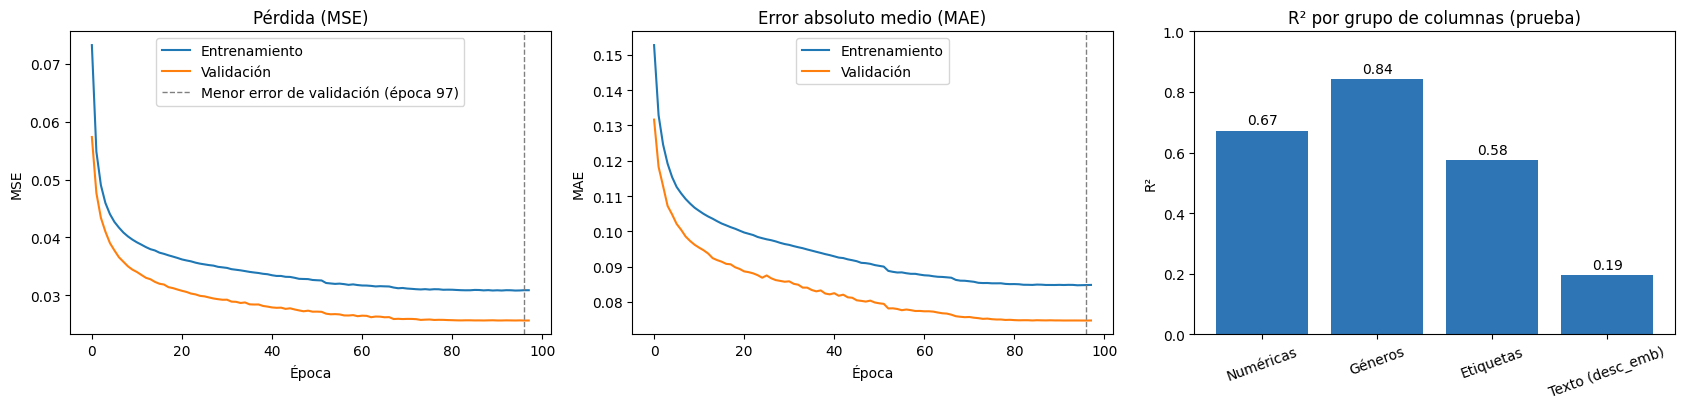

Embeddings: 22747 juegos x 32 dimensiones (32 dimensiones activas)

Coincidencia con los 5 vecinos más cercanos (1000 juegos de prueba):


,Vecinos al azar (mínimo),Embedding de 32 dim (nuestro),Columnas originales (234) (techo)
Coincidencia de géneros,0.246,0.760,0.755
Coincidencia de etiquetas,0.136,0.443,0.502



Counter-Strike 2  ['Action', 'Free To Play']
   0.874  World of Tanks Blitz  ['Action', 'Massively Multiplayer', 'Simulation']
   0.845  Battlefield 4  ['Action']
   0.845  Day of Defeat: Source  ['Action']
   0.837  Counter-Strike: Source  ['Action']
   0.836  Warface: Clutch  ['Action', 'Massively Multiplayer', 'Free To Play']

The Witcher 3: Wild Hunt  ['RPG']
   0.924  Risen 3 - Titan Lords  ['RPG']
   0.919  The Witcher 2: Assassins of Kings Enhanced Edition  ['RPG']
   0.912  The Elder Scrolls V: Skyrim  ['RPG']
   0.894  Pillars of Eternity II: Deadfire  ['RPG']
   0.887  The Elder Scrolls V: Skyrim Special Edition  ['RPG']

Stardew Valley  ['Indie', 'RPG', 'Simulation']
   0.746  Staxel  ['Indie', 'RPG', 'Simulation']
   0.723  Roots of Pacha  ['Indie', 'RPG', 'Simulation']
   0.697  APICO  ['Casual', 'Simulation']
   0.693  Farm Together  ['Casual', 'Indie', 'Simulation']
   0.685  The Escapists 2  ['Indie', 'Simulation', 'Strategy']

Euro Truck Simulator 2  ['Indie', 'Simula

In [ ]:
# 7. Evaluación
# 7.1 Error de reconstrucción por conjunto.
# El conjunto de prueba no interviene en el entrenamiento ni en la selección de época.
mean_vector = X_train.mean(axis=0, keepdims=True)

def evaluar(nombre, X):
    mse, mae = autoencoder.evaluate(X, X, verbose=0)
    base_mse = float(np.mean((X - mean_vector) ** 2))
    return {"Conjunto": nombre, "MSE": mse, "MAE": mae,
            "MSE línea base": base_mse, "Reducción vs base": f"{100 * (1 - mse / base_mse):.1f}%"}

tabla_error = pd.DataFrame([evaluar("Entrenamiento", X_train), evaluar("Validación", X_val), evaluar("Prueba", X_test)])
print("Error de reconstrucción (línea base = predecir siempre el juego promedio):")
display(tabla_error.round(5))

# 7.2 R² por grupo de columnas sobre el conjunto de prueba.
# R² = 1 - SSE / SST por columna, agregado por grupo (1: reconstrucción exacta; 0: equivale a predecir la media).
X_test_rec = autoencoder.predict(X_test, verbose=0)
sse = ((X_test - X_test_rec) ** 2).sum(axis=0)
sst = ((X_test - X_test.mean(axis=0)) ** 2).sum(axis=0)

grupos = {
    "Numéricas": [i for i, c in enumerate(GAME_FEATURE_COLUMNS) if c in numeric_cols],
    "Géneros": [i for i, c in enumerate(GAME_FEATURE_COLUMNS) if c.startswith("genre_")],
    "Etiquetas": [i for i, c in enumerate(GAME_FEATURE_COLUMNS) if c.startswith("tag_")],
    "Texto (desc_emb)": [i for i, c in enumerate(GAME_FEATURE_COLUMNS) if c.startswith("desc_emb_")],
}
r2_grupos = {g: float(1 - sse[idx].sum() / sst[idx].sum()) for g, idx in grupos.items()}
print("\nR² por grupo de columnas (conjunto de prueba):")
for g, v in r2_grupos.items():
    print(f"  {g:18s} {v:.3f}")

# 7.3 Curvas de entrenamiento y R² por grupo
fig, axes = plt.subplots(1, 3, figsize=(17, 4.2))
mejor_epoca = int(np.argmin(history.history["val_loss"]))

axes[0].plot(history.history["loss"], label="Entrenamiento")
axes[0].plot(history.history["val_loss"], label="Validación")
axes[0].axvline(mejor_epoca, color="gray", linestyle="--", linewidth=1, label=f"Menor error de validación (época {mejor_epoca + 1})")
axes[0].set_title("Pérdida (MSE)"); axes[0].set_xlabel("Época"); axes[0].set_ylabel("MSE"); axes[0].legend()

axes[1].plot(history.history["mae"], label="Entrenamiento")
axes[1].plot(history.history["val_mae"], label="Validación")
axes[1].axvline(mejor_epoca, color="gray", linestyle="--", linewidth=1)
axes[1].set_title("Error absoluto medio (MAE)"); axes[1].set_xlabel("Época"); axes[1].set_ylabel("MAE"); axes[1].legend()

barras = axes[2].bar(list(r2_grupos.keys()), list(r2_grupos.values()), color="#2E75B6")
axes[2].set_ylim(0, 1); axes[2].set_title("R² por grupo de columnas (prueba)"); axes[2].set_ylabel("R²")
axes[2].tick_params(axis="x", rotation=20)
for b, v in zip(barras, r2_grupos.values()):
    axes[2].text(b.get_x() + b.get_width() / 2, v + 0.02, f"{v:.2f}", ha="center")
plt.tight_layout()
plt.show()

# 7.4 Calidad del espacio latente.
# Métrica: coincidencia (Jaccard) de géneros / etiquetas entre un juego y sus K vecinos más cercanos
# por coseno. Referencias: vecinos aleatorios (mínimo) y coseno sobre las columnas originales (techo).
emb_all = encoder.predict(game_vectors, batch_size=2048, verbose=0)
dims_activas = int((emb_all.max(axis=0) > 1e-6).sum())
print(f"Embeddings: {emb_all.shape[0]} juegos x {emb_all.shape[1]} dimensiones ({dims_activas} dimensiones activas)")

def normalizar(M):
    return M / np.maximum(np.linalg.norm(M, axis=1, keepdims=True), 1e-8)

emb_norm = normalizar(emb_all)
raw_norm = normalizar(game_vectors)

def jaccard(a, b):
    a, b = set(a), set(b)
    return len(a & b) / len(a | b) if (a | b) else 0.0

generos = df_model["genres_list"].tolist()
etiquetas = df_model["tags_list"].tolist()
nombres = df_model["name"].tolist()
rng = np.random.default_rng(SEED)
consultas = rng.choice(idx_test, size=min(1000, len(idx_test)), replace=False)   # consultas tomadas del conjunto de prueba
K = 5

def acuerdo(M, listas):
    sims = M[consultas] @ M.T
    sims[np.arange(len(consultas)), consultas] = -np.inf          # excluye el propio juego
    vecinos = np.argpartition(-sims, K, axis=1)[:, :K]
    return float(np.mean([np.mean([jaccard(listas[q], listas[j]) for j in fila]) for q, fila in zip(consultas, vecinos)]))

azar = {n: float(np.mean([np.mean([jaccard(l[q], l[j]) for j in rng.choice(len(l), K)]) for q in consultas]))
        for n, l in (("géneros", generos), ("etiquetas", etiquetas))}
tabla_vecinos = pd.DataFrame({
    "Vecinos al azar (mínimo)": [azar["géneros"], azar["etiquetas"]],
    f"Embedding de {emb_all.shape[1]} dim (nuestro)": [acuerdo(emb_norm, generos), acuerdo(emb_norm, etiquetas)],
    f"Columnas originales ({GAME_DIM}) (techo)": [acuerdo(raw_norm, generos), acuerdo(raw_norm, etiquetas)],
}, index=["Coincidencia de géneros", "Coincidencia de etiquetas"])
print(f"\nCoincidencia con los {K} vecinos más cercanos (1000 juegos de prueba):")
display(tabla_vecinos.round(3))

# 7.5 Inspección cualitativa de vecinos
# buscar_juego: coincidencia exacta o por subcadena; ante varias, el de más reseñas.
def buscar_juego(nombre):
    n = nombre.lower()
    exactos = [i for i, x in enumerate(nombres) if x.lower() == n]
    parciales = [i for i, x in enumerate(nombres) if n in x.lower()]
    candidatos = exactos or parciales
    if not candidatos:
        return None
    return max(candidatos, key=lambda i: df_model["review_count"].values[i])

def vecinos_de(nombre, k=5):
    i = buscar_juego(nombre)
    if i is None:
        print(f"'{nombre}' no está en el catálogo"); return
    sims = emb_norm @ emb_norm[i]
    sims[i] = -np.inf
    print(f"\n{nombres[i]}  {generos[i][:3]}")
    for j in np.argsort(-sims)[:k]:
        print(f"   {sims[j]:.3f}  {nombres[j]}  {generos[j][:3]}")

for juego in ["Counter-Strike 2", "The Witcher 3: Wild Hunt", "Stardew Valley", "Euro Truck Simulator 2", "ELDEN RING"]:
    vecinos_de(juego)

## 8. Ajustar y desplegar

Componentes de la celda:

- **Perfil:** las respuestas del cuestionario se convierten en un vector con las mismas columnas que un videojuego; las columnas sin respuesta toman el valor medio del catálogo.
- **Filtros duros:** plataforma, presupuesto, edad, idioma, requisitos obligatorios y contenido a evitar se aplican antes del ranking.
- **Puntaje:** mezcla de la similitud sobre las columnas (coseno entre desviaciones respecto al juego promedio), la similitud en el espacio latente del encoder y, si el usuario las escribe, la similitud TF-IDF con palabras clave.
- **Ajuste:** el peso de las columnas numéricas y el peso del embedding se seleccionan con 80 perfiles aleatorios.
- **Exportación:** modelos, embeddings, preprocesadores y catálogo reducido en un `.zip`.
- **Punto 9:** ejecuta el cuestionario interactivo.

In [ ]:
# 8. Ajuste de hiperparámetros, motor de recomendación y despliegue
# 8.1 Utilidades y espacio latente del catálogo
def normalizar(M):
    return M / np.maximum(np.linalg.norm(M, axis=-1, keepdims=True), 1e-8)

def zscore(S):
    # Estandariza cada fila para poder combinar similitudes con distinta escala
    return (S - S.mean(axis=1, keepdims=True)) / (S.std(axis=1, keepdims=True) + 1e-9)

emb_all = encoder.predict(game_vectors, batch_size=2048, verbose=0)
emb_norm = normalizar(emb_all)        # catálogo normalizado en el espacio latente

col_idx = {c: i for i, c in enumerate(GAME_FEATURE_COLUMNS)}
pos_num = {c: i for i, c in enumerate(numeric_cols)}
NUM_IDX = np.array([col_idx[c] for c in numeric_cols])
perfil_neutro = X_train.mean(axis=0)  # vector medio del catálogo; valor de las columnas sin respuesta del usuario
N_JUEGOS = len(df_model)

# Similitud sobre columnas: coseno entre desviaciones respecto a perfil_neutro. Las columnas sin
# respuesta valen 0 en la desviación y no influyen en el coseno. Las columnas numéricas se multiplican
# por PESO_NUMERICAS: con cientos de columnas multi-hot, sin ese factor su aporte al coseno es mínimo.
# El valor se selecciona en 8.6.
def desviacion(M, w_num):
    D = np.array(M, dtype="float32") - perfil_neutro
    D[:, NUM_IDX] *= w_num
    return D

def preparar_columnas(w_num):
    global PESO_NUMERICAS, raw_norm
    PESO_NUMERICAS = w_num
    raw_norm = normalizar(desviacion(game_vectors, w_num))

preparar_columnas(2.0)

def a_escala(col, valor):
    # Convierte un valor en unidades reales a la escala [0, 1] del scaler_games
    j = pos_num[col]
    rango = scaler_games.data_max_[j] - scaler_games.data_min_[j]
    return float(np.clip((valor - scaler_games.data_min_[j]) / max(rango, 1e-9), 0, 1))

def cuantil(col, p):
    return float(df_model[col].quantile(p))

# Matriz booleana juego x etiqueta con todas las etiquetas del dataset (no solo las columnas de la red);
# se usa en los filtros del cuestionario y en la columna 'Coincide en'
mlb_todas = MultiLabelBinarizer()
MATRIZ_TAGS = mlb_todas.fit_transform(df_model["tags_list"]).astype(bool)
TAG_COL = {t: i for i, t in enumerate(mlb_todas.classes_)}
CONTEO_TAG = MATRIZ_TAGS.sum(axis=0)

def tiene_tag(t):
    return MATRIZ_TAGS[:, TAG_COL[t]] if t in TAG_COL else np.zeros(N_JUEGOS, dtype=bool)

def tiene_alguna(tags):
    out = np.zeros(N_JUEGOS, dtype=bool)
    for t in tags:
        out |= tiene_tag(t)
    return out

def opciones_validas(opciones, minimo=150):
    # Descarta opciones cuya etiqueta tenga menos de `minimo` juegos en el dataset
    return [(et, tags) for et, tags in opciones
            if any(t in TAG_COL and CONTEO_TAG[TAG_COL[t]] >= minimo for t in (tags if isinstance(tags, list) else [tags]))]

# 8.2 Catálogo del cuestionario: cada opción apunta a un género o etiqueta existente en el dataset
GENEROS_OFERTA = [g for g in ["Action", "Adventure", "Indie", "Casual", "RPG", "Strategy", "Simulation",
                              "Sports", "Racing", "Massively Multiplayer"] if g in top_genres]
EXPERIENCIAS = {"Un jugador": ["Single-player"], "Multijugador": ["Multi-player"], "Cooperativo": ["Co-op", "Online Co-op"],
                "Competitivo (PvP)": ["PvP", "Online PvP"], "Local / pantalla dividida": ["Shared/Split Screen", "Local Co-Op"]}
CATEGORIAS_EXPERIENCIA = sorted({t for v in EXPERIENCIAS.values() for t in v})

GRUPOS_TAGS = {   # clave: (pregunta, [(texto mostrado, etiqueta del dataset)])
    "estilo": ("¿Qué estilo visual te gusta?", [
        ("Pixel art", "Pixel Graphics"), ("2D", "2D"), ("3D", "3D"), ("Tierno / lindo", "Cute"), ("Colorido", "Colorful"),
        ("Realista", "Realistic"), ("Estilizado", "Stylized"), ("Anime", "Anime"), ("Retro", "Retro"),
        ("Dibujo animado", "Cartoony"), ("Dibujado a mano", "Hand-drawn"), ("Minimalista", "Minimalist"), ("Oscuro", "Dark")]),
    "perspectiva": ("¿Qué perspectiva de cámara prefieres?", [
        ("Primera persona", "First-Person"), ("Tercera persona", "Third Person"), ("Vista desde arriba", "Top-Down"),
        ("Isométrica", "Isometric"), ("Vista lateral (side-scroller)", "Side Scroller")]),
    "tematica": ("¿Qué temática te atrae?", [
        ("Fantasía", "Fantasy"), ("Ciencia ficción", "Sci-fi"), ("Terror", "Horror"), ("Terror psicológico", "Psychological Horror"),
        ("Espacio", "Space"), ("Zombis", "Zombies"), ("Postapocalíptico", "Post-apocalyptic"), ("Cyberpunk", "Cyberpunk"),
        ("Medieval", "Medieval"), ("Histórico", "Historical"), ("Guerra", "War"), ("Misterio", "Mystery"),
        ("Detectives", "Detective"), ("Magia", "Magic"), ("Futurista", "Futuristic"), ("Fantasía oscura", "Dark Fantasy"),
        ("Surrealista", "Surreal")]),
    "accion": ("¿Qué tipo de acción / combate buscas?", [
        ("Shooters", "Shooter"), ("Primera persona (FPS)", "FPS"), ("Shooter en tercera persona", "Third-Person Shooter"),
        ("Hack and slash", "Hack and Slash"), ("Peleas (fighting)", "Fighting"), ("Sigilo", "Stealth"),
        ("Bullet hell", "Bullet Hell"), ("Souls-like (muy difíciles)", "Souls-like"), ("Battle royale", "Battle Royale"),
        ("Combate", "Combat")]),
    "estrategia": ("¿Qué tipo de estrategia / gestión te interesa?", [
        ("Estrategia por turnos", "Turn-Based Strategy"), ("Estrategia en tiempo real (RTS)", "RTS"), ("Táctica", "Tactical"),
        ("Gestión", "Management"), ("Constructores de ciudades", "City Builder"), ("Construir bases", "Base-Building"),
        ("Torres de defensa", "Tower Defense"), ("Gestión de recursos", "Resource Management"), ("Economía", "Economy"),
        ("Juegos de cartas", "Card Game"), ("Construcción de mazos", "Deckbuilding")]),
    "aventura": ("¿Qué mecánicas de aventura / exploración prefieres?", [
        ("Mundo abierto", "Open World"), ("Exploración", "Exploration"), ("Sandbox", "Sandbox"), ("Supervivencia", "Survival"),
        ("Puzles", "Puzzle"), ("Plataformas", "Platformer"), ("Metroidvania", "Metroidvania"), ("Point & click", "Point & Click"),
        ("Simuladores de caminar", "Walking Simulator"), ("Novela visual", "Visual Novel"), ("Roguelike", "Rogue-like"),
        ("Roguelite", "Rogue-lite"), ("Mazmorras", "Dungeon Crawler"), ("Generación procedural", "Procedural Generation"),
        ("Crafteo", "Crafting"), ("Construcción", "Building"), ("Conducción", "Driving"), ("Carreras", "Racing"), ("Ritmo / música", "Rhythm")]),
    "rol": ("¿Qué tipo de rol (RPG) te gusta?", [
        ("JRPG", "JRPG"), ("RPG de acción", "Action RPG"), ("RPG de estrategia", "Strategy RPG"),
        ("Personalizar personaje", "Character Customization"), ("Combate por turnos", "Turn-Based Combat")]),
    "narrativa": ("¿Qué te importa de la historia y el ambiente?", [
        ("Historia profunda", "Story Rich"), ("Atmosférico", "Atmospheric"), ("Decisiones que importan", "Choices Matter"),
        ("Varios finales", "Multiple Endings"), ("Gran banda sonora", "Great Soundtrack"), ("Humor", "Funny"),
        ("Drama", "Drama"), ("Protagonista femenina", "Female Protagonist"), ("Apto para familia", "Family Friendly"),
        ("Rejugable", "Replay Value")]),
    "ritmo": ("¿Qué ritmo o dificultad prefieres?", [
        ("Difícil / desafiante", "Difficult"), ("Relajante", "Relaxing"), ("Ritmo rápido", "Fast-Paced"),
        ("Acogedor (cozy)", "Cozy"), ("Reconfortante (wholesome)", "Wholesome"), ("Casual", "Casual")]),
}
GRUPOS_TAGS = {k: (preg, opciones_validas(ops)) for k, (preg, ops) in GRUPOS_TAGS.items()}

REQUISITOS = [("Soporte completo de mando", ["Full controller support"]), ("Mods (Steam Workshop)", ["Steam Workshop"]),
              ("Guardado en la nube", ["Steam Cloud"]), ("Logros de Steam", ["Steam Achievements"]),
              ("Jugar con amigos (Remote Play Together)", ["Remote Play Together"]), ("Subtítulos", ["Captions available"]),
              ("Realidad virtual (VR)", ["VR", "VR Only", "VR Supported"]), ("Multijugador entre plataformas", ["Cross-Platform Multiplayer"]),
              ("Editor de niveles", ["Includes level editor", "Level Editor"])]
REQUISITOS = opciones_validas(REQUISITOS)
EVITAR = [("Violencia explícita / gore", ["Gore", "Violent"]), ("Contenido sexual / desnudez", ["Sexual Content", "Nudity", "Mature"]),
          ("Terror", ["Horror", "Psychological Horror", "Survival Horror"])]
EVITAR = opciones_validas(EVITAR)
IDIOMAS = {"Español": "spanish", "Inglés": "english", "Francés": "french", "Alemán": "german",
           "Portugués (Brasil)": "portuguese - brazil", "Italiano": "italian", "Japonés": "japanese",
           "Ruso": "russian", "Chino simplificado": "simplified chinese", "Coreano": "korean"}
TIENE_IDIOMA = {nombre: df_model["languages_list"].apply(lambda l, s=s: any(s in x.lower() for x in l)).values
                for nombre, s in IDIOMAS.items()}

POPULARIDAD_Q = {"nicho": 0.15, "media": 0.50, "alta": 0.99}        # percentil de log_owners, log_ccu, log_recommendations y log_review_count
COMUNIDAD_Q = {"media": 0.85, "alta": 0.97}                         # percentil de log_ccu
RESENAS = {"alta": (0.95, 0.75), "media": (0.80, 0.60)}             # (review_score objetivo, percentil de log_review_count)
METACRITIC = {"alta": 85, "media": 70}   # metacritic_score objetivo
ANTIGUEDAD = {"reciente": 1.5, "media": 5.0, "clasico": 12.0}       # años desde el lanzamiento
LOGROS_Q = {"alta": 0.90, "media": 0.60}   # percentil de log_achievements
ESTUDIO_Q = {"pequeno": 0.10, "grande": 0.95}   # percentil de developer_popularity y publisher_popularity

# 8.3 Conversión de respuestas a vector de perfil (mismas columnas que game_vectors)
def etiquetas_pedidas(r):
    pedidas = [t for e in r.get("experiencia", []) for t in EXPERIENCIAS[e]]
    for clave in GRUPOS_TAGS:
        pedidas += r.get(clave, [])
    return list(dict.fromkeys(pedidas))

def construir_perfil(r):
    """Convierte las respuestas en un vector con las mismas columnas que game_vectors.
    Las columnas sin respuesta conservan el valor de perfil_neutro."""
    v = perfil_neutro.copy()
    def poner(col, valor):
        v[col_idx[col]] = a_escala(col, valor)
    # Géneros y experiencia ofrecidos: 1 si fue elegido, 0 si no. El resto de columnas de género/etiqueta no se modifica.
    if r.get("generos"):
        for g in GENEROS_OFERTA:
            v[col_idx["genre_" + g]] = 1.0 if g in r["generos"] else 0.0
    if r.get("experiencia"):
        elegidas = set(t for e in r["experiencia"] for t in EXPERIENCIAS[e])
        for t in CATEGORIAS_EXPERIENCIA:
            if "tag_" + t in col_idx:
                v[col_idx["tag_" + t]] = 1.0 if t in elegidas else 0.0
    for clave in GRUPOS_TAGS:
        for t in r.get(clave, []):
            if "tag_" + t in col_idx:
                v[col_idx["tag_" + t]] = 1.0
    # Presupuesto -> precio objetivo (50% del máximo) en escala logarítmica, igual que price_log
    if r.get("precio_max") is not None:
        objetivo = r["precio_max"] * 0.5
        poner("price_log", np.log1p(objetivo)); poner("initialprice_log", np.log1p(objetivo)); poner("price_known", 1)
        if r["precio_max"] == 0:
            poner("is_free", 1)
    if r.get("solo_ofertas"):
        poner("discount_ratio", 0.5)
    # Preferencias numéricas: se fija el valor objetivo (percentil del catálogo o valor absoluto) y la bandera *_known
    if r.get("resenas") in RESENAS:
        puntaje, p_cuenta = RESENAS[r["resenas"]]
        poner("review_score", puntaje); poner("review_known", 1)
        poner("log_review_count", cuantil("log_review_count", p_cuenta))
    if r.get("popularidad") in POPULARIDAD_Q:
        for c in ["log_owners", "log_ccu", "log_recommendations", "log_review_count"]:
            poner(c, cuantil(c, POPULARIDAD_Q[r["popularidad"]]))
        poner("owners_known", 1); poner("review_known", 1)
    if r.get("comunidad") in COMUNIDAD_Q:
        poner("log_ccu", cuantil("log_ccu", COMUNIDAD_Q[r["comunidad"]]))
    if r.get("metacritic") in METACRITIC:
        poner("metacritic_score", METACRITIC[r["metacritic"]]); poner("metacritic_known", 1)
    if r.get("antiguedad") in ANTIGUEDAD:
        poner("game_age_years", ANTIGUEDAD[r["antiguedad"]]); poner("release_date_unknown", 0)
    if r.get("logros") in LOGROS_Q:
        poner("log_achievements", cuantil("log_achievements", LOGROS_Q[r["logros"]]))
    if r.get("estudio") in ESTUDIO_Q:
        for c in ["developer_popularity", "publisher_popularity"]:
            poner(c, cuantil(c, ESTUDIO_Q[r["estudio"]]))
    if r.get("idiomas"):
        if "Español" in r["idiomas"]: poner("has_spanish", 1)
        if "Inglés" in r["idiomas"]: poner("has_english", 1)
    return v

# 8.4 Restricciones duras: se aplican como filtro previo al ranking
es_juego = ~df_model["genres_list"].apply(lambda l: any(g in SOFTWARE for g in l)).values   # excluye aplicaciones que no son juegos
es_early_access = df_model["genres_list"].apply(lambda l: "Early Access" in l).values | tiene_tag("Early Access")
PRECIO_CONOCIDO = df_model["price_known"].values == 1
PRECIO_USD = df_model["price_usd"].values
ES_GRATIS = (df_model["is_free"].values == 1) | (PRECIO_CONOCIDO & (PRECIO_USD == 0))

def construir_mascara(r):
    ok = es_juego.copy()
    if not r.get("incluir_no_lanzados"):
        ok &= df_model["is_unreleased"].values == 0
    if r.get("plataforma") in ("windows", "mac", "linux"):
        ok &= df_model["platforms_" + r["plataforma"]].values == 1
    p = r.get("precio_max")
    incluir_sin_precio = r.get("incluir_sin_precio", True)
    if p is not None:
        if p == 0:
            ok &= ES_GRATIS                                    # precio_max == 0: solo gratuitos; un precio desconocido no cuenta como gratis
        else:
            dentro = (PRECIO_CONOCIDO & (PRECIO_USD <= p)) | ES_GRATIS
            if incluir_sin_precio:
                dentro |= ~PRECIO_CONOCIDO                     # los juegos sin precio pasan el filtro de presupuesto (ver incluir_sin_precio)
            ok &= dentro
    elif not incluir_sin_precio:
        ok &= PRECIO_CONOCIDO | ES_GRATIS
    if r.get("solo_ofertas"):
        ok &= df_model["discount"].values > 0
    if r.get("early_access") == "no":
        ok &= ~es_early_access
    elif r.get("early_access") == "solo":
        ok &= es_early_access
    if r.get("edad_max") is not None:                          # required_age = 0 (sin clasificar) siempre pasa
        ok &= df_model["required_age"].values <= r["edad_max"]
    if r.get("idiomas"):
        alguno = np.zeros(N_JUEGOS, dtype=bool)
        for nombre in r["idiomas"]:
            alguno |= TIENE_IDIOMA[nombre]
        ok &= alguno
    for tags in r.get("requisitos", []):                       # cada requisito seleccionado es obligatorio (AND)
        ok &= tiene_alguna(tags)
    for tags in r.get("evitar", []):                           # se excluye el juego si tiene alguna etiqueta del grupo
        ok &= ~tiene_alguna(tags)
    return ok

# 8.5 Puntaje: mezcla de similitud sobre columnas, similitud en el espacio latente y (opcional) palabras clave
def puntuar_lote(perfiles, peso_red):
    P = np.asarray(perfiles, dtype="float32")
    cos_col = normalizar(desviacion(P, PESO_NUMERICAS)) @ raw_norm.T
    cos_emb = normalizar(encoder.predict(P, verbose=0)) @ emb_norm.T
    z = (1 - peso_red) * zscore(cos_col) + peso_red * zscore(cos_emb)
    return z, cos_col, cos_emb

# Traducción es->en de términos frecuentes: el índice de búsqueda (celda 2.2) está construido con texto en inglés
ES_EN = {"zombi": "zombie", "zombis": "zombies", "espacio": "space", "granja": "farming", "granjas": "farming",
         "agricultura": "farming", "terror": "horror", "carreras": "racing", "coches": "cars", "carros": "cars",
         "futbol": "soccer football", "guerra": "war", "magia": "magic", "dragon": "dragon", "dragones": "dragons",
         "pirata": "pirate", "piratas": "pirates", "vampiros": "vampires", "misterio": "mystery", "cocina": "cooking",
         "construir": "building", "supervivencia": "survival", "historia": "story", "dinosaurios": "dinosaurs",
         "ciudad": "city", "musica": "music", "baile": "dance", "pesca": "fishing", "pescar": "fishing",
         "camiones": "trucks", "trenes": "trains", "aviones": "airplanes flight", "submarino": "submarine",
         "bosque": "forest", "apocalipsis": "apocalypse", "superheroes": "superhero", "policia": "police",
         "escuela": "school", "amor": "romance", "citas": "dating", "mascotas": "pets", "gatos": "cats",
         "perros": "dogs", "fantasia": "fantasy", "robots": "robots", "robot": "robot", "ninja": "ninja",
         "samurai": "samurai", "cooperativo": "co-op", "estrategia": "strategy", "aventura": "adventure",
         "puzzle": "puzzle", "puzles": "puzzle", "mundo": "world", "libre": "open", "oscuro": "dark",
         "medieval": "medieval", "ciencia": "science", "ficcion": "fiction", "nave": "spaceship", "naves": "spaceships"}

def sin_acentos(t):
    import unicodedata
    return "".join(c for c in unicodedata.normalize("NFKD", t) if not unicodedata.combining(c))

# Similitud coseno TF-IDF entre la consulta y el índice de búsqueda; devuelve (z-score, similitud cruda)
def puntaje_palabras(consulta):
    palabras = [ES_EN.get(w, w) for w in re.findall(r"[a-z0-9\-']+", sin_acentos(consulta.lower()))]
    q = tfidf_busqueda.transform([" ".join(palabras)])
    sim = (matriz_busqueda @ q.T).toarray().ravel()
    return zscore(sim.reshape(1, -1))[0], sim

# 8.6 Selección de pesos con 80 perfiles de usuario aleatorios.
# Métrica: fracción media de las 20 primeras recomendaciones que cumplen las preferencias declaradas.
# Mide coherencia con el perfil, no satisfacción de usuarios reales.
generos_juego = df_model["genres_list"].tolist()
etiquetas_juego = df_model["tags_list"].tolist()
puntaje_resenas = df_model["review_score"].values
log_duenos = df_model["log_owners"].values
p25, p75 = np.quantile(log_duenos, 0.25), np.quantile(log_duenos, 0.75)

def perfil_aleatorio(rng):
    r = {"generos": list(rng.choice(GENEROS_OFERTA, size=rng.integers(1, 4), replace=False))}
    if rng.random() < 0.7:
        r["experiencia"] = list(rng.choice(list(EXPERIENCIAS), size=rng.integers(1, 3), replace=False))
    for clave in rng.choice(list(GRUPOS_TAGS), size=rng.integers(1, 4), replace=False):
        ops = GRUPOS_TAGS[clave][1]
        r[clave] = [ops[i][1] for i in rng.choice(len(ops), size=min(len(ops), rng.integers(1, 3)), replace=False)]
    r["precio_max"] = rng.choice([0, 10, 20, 40, 60, None])
    r["precio_max"] = None if r["precio_max"] is None else float(r["precio_max"])
    r["resenas"] = str(rng.choice(["alta", "media", "ninguna"]))
    r["popularidad"] = str(rng.choice(["alta", "media", "nicho", "ninguna"]))
    return r

def cumplimiento(r, top):
    # Fracción de juegos recomendados que cumplen cada preferencia declarada; se promedian
    f = [np.mean([any(g in generos_juego[j] for g in r["generos"]) for j in top])]
    if r.get("experiencia"):
        cats = {t for e in r["experiencia"] for t in EXPERIENCIAS[e]}
        f.append(np.mean([any(t in etiquetas_juego[j] for t in cats) for j in top]))
    pedidas = [t for clave in GRUPOS_TAGS for t in r.get(clave, [])]
    if pedidas:
        f.append(np.mean([any(t in etiquetas_juego[j] for t in pedidas) for j in top]))
    if r["resenas"] == "alta":  f.append(np.mean(puntaje_resenas[top] >= 0.80))
    if r["resenas"] == "media": f.append(np.mean(puntaje_resenas[top] >= 0.70))
    if r["popularidad"] == "alta":  f.append(np.mean(log_duenos[top] >= p75))
    if r["popularidad"] == "nicho": f.append(np.mean(log_duenos[top] <= p25))
    return float(np.mean(f))

rng_ajuste = np.random.default_rng(SEED)
perfiles_prueba = [perfil_aleatorio(rng_ajuste) for _ in range(80)]
P_prueba = np.array([construir_perfil(r) for r in perfiles_prueba])
mascaras_prueba = [construir_mascara(r) for r in perfiles_prueba]

def cumplimiento_medio(peso_red):
    z, _, _ = puntuar_lote(P_prueba, peso_red)
    c = [cumplimiento(r, np.argsort(-np.where(m, s, -np.inf))[:20]) for r, s, m in zip(perfiles_prueba, z, mascaras_prueba)]
    return round(float(np.mean(c)), 3)

# Paso 1: peso de las columnas numéricas (sin red). Se elige el de mayor cumplimiento; en empate, el menor.
filas = []
for w_num in [1.0, 2.0, 3.0, 5.0]:
    preparar_columnas(w_num)
    filas.append({"Peso de columnas numéricas": w_num, "Cumplimiento de preferencias": cumplimiento_medio(0.0)})
tabla_numericas = pd.DataFrame(filas)
mejor_num = tabla_numericas["Cumplimiento de preferencias"].max()
mejor_w = float(tabla_numericas.loc[tabla_numericas["Cumplimiento de preferencias"] == mejor_num, "Peso de columnas numéricas"].min())
preparar_columnas(mejor_w)
tabla_numericas["Elegido"] = np.where(tabla_numericas["Peso de columnas numéricas"] == mejor_w, "<--", "")
print("Ajuste 1: peso de las columnas numéricas (80 perfiles aleatorios, 20 recomendaciones cada uno):")
display(tabla_numericas)

# Paso 2: peso del embedding en la mezcla
PESOS_RED = [0.0, 0.1, 0.25, 0.5, 0.75, 1.0]
tabla_ajuste = pd.DataFrame([{"Peso de la red": w, "Cumplimiento de preferencias": cumplimiento_medio(w)} for w in PESOS_RED])

# Se elige el mayor peso del embedding cuyo cumplimiento no baja más de TOLERANCIA respecto al máximo.
TOLERANCIA = 0.01
mejor = tabla_ajuste["Cumplimiento de preferencias"].max()
PESO_RED = float(tabla_ajuste.loc[tabla_ajuste["Cumplimiento de preferencias"] >= mejor - TOLERANCIA, "Peso de la red"].max())
PESO_TEXTO = 0.35      # peso de la búsqueda por palabras clave en el puntaje final (valor fijo, sin ajuste)
tabla_ajuste["Elegido"] = np.where(tabla_ajuste["Peso de la red"] == PESO_RED, "<--", "")
print("\nAjuste 2: peso de la red neuronal en la mezcla:")
display(tabla_ajuste)
print(f"Elegidos -> columnas numéricas x{PESO_NUMERICAS:g} | red {PESO_RED}  (0 = solo columnas, 1 = solo embedding)")

# 8.7 Recomendación
def precio_texto(j):
    if ES_GRATIS[j]:
        return "Gratis"
    if not PRECIO_CONOCIDO[j]:
        return "Sin precio en Steam"
    desc = df_model["discount"].values[j]
    return f"${PRECIO_USD[j]:.2f}" + (f" (-{int(desc)}%)" if desc > 0 else "")

def recomendar(respuestas, k=None, peso_red=None, usar_restricciones=True):
    k = k or respuestas.get("k") or TOP_K_RECOMMEND
    w = PESO_RED if peso_red is None else peso_red
    z, cos_col, cos_emb = puntuar_lote(construir_perfil(respuestas).reshape(1, -1), w)
    puntaje = z[0].copy()
    palabras = respuestas.get("palabras_clave", "").strip()
    if palabras:
        z_txt, _ = puntaje_palabras(palabras)
        puntaje = (1 - PESO_TEXTO) * puntaje + PESO_TEXTO * z_txt
    # Los juegos que no pasan los filtros duros reciben puntaje -inf
    if usar_restricciones:
        puntaje[~construir_mascara(respuestas)] = -np.inf
    top = [j for j in np.argsort(-puntaje)[:k] if np.isfinite(puntaje[j])]
    pedidas = etiquetas_pedidas(respuestas)
    # Géneros y etiquetas pedidos que el juego posee (máximo 4)
    def coincide(j):
        c = [g for g in respuestas.get("generos", []) if g in generos_juego[j]] + [t for t in pedidas if t in etiquetas_juego[j]]
        return ", ".join(c[:4])
    tabla = pd.DataFrame({
        "Juego": df_model["name"].values[top],
        "Géneros": [", ".join(generos_juego[j][:3]) for j in top],
        "Precio": [precio_texto(j) for j in top],
        "Reseñas": [(f"{100 * puntaje_resenas[j]:.0f}%" if df_model["review_known"].values[j] else "s/d") for j in top],
        "Año": [str(df_model["release_date"].values[j])[:4] or "s/d" for j in top],
        "Coincide en": [coincide(j) for j in top],
        "Sim. columnas": cos_col[0][top].round(3),
        "Sim. red": cos_emb[0][top].round(3),
        "Steam": [("store.steampowered.com/app/" + str(df_model["appid"].values[j])) if df_model["appid_real"].values[j]
                  else "(sin enlace: ID inventado)" for j in top],
    })
    tabla.index = range(1, len(tabla) + 1)
    return tabla

# 8.8 Ejemplos de uso
demos = {
    "RPG de fantasía en solitario, historia profunda, reseñas altas, hasta $30, Windows": {
        "generos": ["RPG", "Adventure"], "experiencia": ["Un jugador"], "plataforma": "windows", "tematica": ["Fantasy"],
        "narrativa": ["Story Rich"], "precio_max": 30.0, "resenas": "alta", "popularidad": "media"},
    "Cozy, relajante, 2D, barato y poco conocido, sin violencia": {
        "generos": ["Casual", "Indie"], "estilo": ["2D", "Cute"], "ritmo": ["Relaxing", "Cozy"],
        "precio_max": 10.0, "resenas": "media", "popularidad": "nicho", "evitar": [tags for et, tags in EVITAR if et.startswith("Violencia")]},
    "Shooter multijugador gratuito, muy popular, de estudio grande, con español": {
        "generos": ["Action"], "experiencia": ["Multijugador"], "plataforma": "windows", "precio_max": 0.0,
        "resenas": "alta", "popularidad": "alta", "idiomas": ["Español"], "estudio": "grande"},
}
for titulo, resp in demos.items():
    print(f"\n=== {titulo} ===")
    display(recomendar(resp))

# 8.9 Cuestionario interactivo (las funciones se definen aquí; la ejecución está en el punto 9)
def preguntar(texto, opciones, multiple=False):
    # opciones: lista de (texto mostrado, valor devuelto). Entrada vacía devuelve [] (multiple) o None
    print(f"\n{texto}")
    for i, (etiqueta, _) in enumerate(opciones, 1):
        print(f"  {i:2d}. {etiqueta}")
    indicacion = "uno o varios números separados por coma" if multiple else "un número"
    while True:
        entrada = input(f"Tu respuesta ({indicacion}; Enter = me da igual): ").strip()
        if not entrada:
            return [] if multiple else None
        try:
            idx = [int(x) for x in entrada.replace(" ", "").split(",") if x]
            if idx and all(1 <= i <= len(opciones) for i in idx) and (multiple or len(idx) == 1):
                valores = [opciones[i - 1][1] for i in idx]
                return valores if multiple else valores[0]
        except ValueError:
            pass
        print(f"  Respuesta no válida: escribe {'números' if multiple else 'un número'} entre 1 y {len(opciones)}, o pulsa Enter.")

def seccion(titulo):
    print("\n" + "=" * 64 + f"\n{titulo}\n" + "=" * 64)

NOMBRES_CLAVE = {"generos": "géneros", "experiencia": "experiencia", "estilo": "estilo", "perspectiva": "cámara",
                 "tematica": "temática", "accion": "acción", "estrategia": "estrategia", "aventura": "aventura",
                 "rol": "rol", "narrativa": "historia/ambiente", "ritmo": "ritmo", "plataforma": "plataforma",
                 "resenas": "reseñas", "popularidad": "popularidad", "comunidad": "comunidad activa",
                 "metacritic": "críticos", "antiguedad": "antigüedad", "logros": "logros", "estudio": "estudio",
                 "idiomas": "idiomas", "early_access": "early access"}

def describir_perfil(r):
    partes = []
    for clave, etiqueta in NOMBRES_CLAVE.items():
        v = r.get(clave)
        if v:
            partes.append(f"{etiqueta}: " + (", ".join(v) if isinstance(v, list) else str(v)))
    if r.get("precio_max") is not None:
        partes.append("presupuesto: " + ("solo gratis" if r["precio_max"] == 0 else f"hasta ${r['precio_max']:g}"))
    if r.get("edad_max") is not None:
        partes.append("edad: " + ("sin clasificación" if r["edad_max"] == 0 else f"hasta {r['edad_max']:g} años"))
    if r.get("solo_ofertas"): partes.append("solo en oferta")
    if r.get("incluir_sin_precio") is False: partes.append("solo con precio confirmado")
    if r.get("incluir_no_lanzados"): partes.append("incluye próximos lanzamientos")
    if r.get("requisitos"): partes.append("requiere: " + ", ".join(t[0] for t in r["requisitos"]))
    if r.get("evitar"): partes.append("evita: " + ", ".join(t[0] for t in r["evitar"]))
    if r.get("palabras_clave"): partes.append(f"palabras clave: «{r['palabras_clave']}»")
    return "; ".join(partes) if partes else "sin preferencias (recomendación general)"

def cuestionario_interactivo():
    niveles = [("Muy importante", "alta"), ("Algo importante", "media"), ("No me importa", None)]
    r, n = {}, 0
    def num():
        nonlocal n
        n += 1
        return f"{n}."

    seccion("A. TIPO DE JUEGO")
    r["generos"] = preguntar(f"{num()} ¿Qué géneros te interesan?", [(g, g) for g in GENEROS_OFERTA], multiple=True)
    r["experiencia"] = preguntar(f"{num()} ¿Qué tipo de experiencia prefieres?", [(e, e) for e in EXPERIENCIAS], multiple=True)
    for clave, (pregunta, ops) in GRUPOS_TAGS.items():
        r[clave] = preguntar(f"{num()} {pregunta}", ops, multiple=True)

    seccion("B. TU EQUIPO, PRESUPUESTO E IDIOMA")
    r["plataforma"] = preguntar(f"{num()} ¿En qué plataforma jugarás?", [("Windows", "windows"), ("Mac", "mac"), ("Linux", "linux")])
    r["precio_max"] = preguntar(f"{num()} ¿Cuál es tu presupuesto máximo por juego?",
                                [("Solo gratis", 0.0), ("Hasta $5", 5.0), ("Hasta $10", 10.0), ("Hasta $20", 20.0),
                                 ("Hasta $40", 40.0), ("Hasta $60", 60.0)])
    r["solo_ofertas"] = bool(preguntar(f"{num()} ¿Quieres ver solo juegos en oferta ahora mismo?", [("Sí, solo en oferta", True)]))
    sin_precio = preguntar(f"{num()} Algunos juegos no tienen precio en Steam (retirados o sin dato). ¿Los incluyo?",
                           [("Sí, incluirlos (el precio no importa para ellos)", True), ("No, solo juegos con precio confirmado", False)])
    r["incluir_sin_precio"] = True if sin_precio is None else sin_precio
    r["idiomas"] = preguntar(f"{num()} ¿En qué idiomas puedes jugar? (el juego debe tener al menos uno)",
                             [(i, i) for i in IDIOMAS], multiple=True)
    r["edad_max"] = preguntar(f"{num()} ¿Qué clasificación de edad aceptas?",
                              [("Solo sin clasificación de edad (todo público)", 0.0), ("Hasta 13 años", 13.0), ("Hasta 17 años", 17.0)])

    seccion("C. CALIDAD, POPULARIDAD Y NOVEDAD")
    r["resenas"] = preguntar(f"{num()} ¿Qué tan importantes son las buenas reseñas?", niveles)
    r["popularidad"] = preguntar(f"{num()} ¿Qué nivel de popularidad buscas?",
                                 [("Poco conocidos (nicho)", "nicho"), ("Intermedios", "media"),
                                  ("Muy populares (el 1% más jugado de Steam)", "alta")])
    r["comunidad"] = preguntar(f"{num()} ¿Quieres una comunidad activa hoy (muchos jugadores conectados)?",
                               [("Muy activa", "alta"), ("Algo activa", "media")])
    r["metacritic"] = preguntar(f"{num()} ¿Qué importancia tiene la puntuación de los críticos (Metacritic)?", niveles)
    r["antiguedad"] = preguntar(f"{num()} ¿Qué antigüedad prefieres?",
                                [("Recientes (1-2 años)", "reciente"), ("De hace unos 5 años", "media"), ("Clásicos (10+ años)", "clasico")])
    r["incluir_no_lanzados"] = bool(preguntar(f"{num()} ¿Incluyo juegos que todavía no se han lanzado?", [("Sí, incluir próximos lanzamientos", True)]))
    r["early_access"] = preguntar(f"{num()} ¿Qué opinas del acceso anticipado (Early Access)?",
                                  [("Solo juegos terminados", "no"), ("Solo juegos en acceso anticipado", "solo")])
    r["logros"] = preguntar(f"{num()} ¿Qué importancia tienen los logros?", niveles)
    r["estudio"] = preguntar(f"{num()} ¿Qué tipo de estudio prefieres?",
                             [("Pequeño / independiente", "pequeno"), ("Grande / con muchos títulos (ej. Valve, Ubisoft)", "grande")])

    seccion("D. REQUISITOS Y CONTENIDO")
    r["requisitos"] = preguntar(f"{num()} ¿Qué características son OBLIGATORIAS en el juego?", REQUISITOS, multiple=True)
    r["evitar"] = preguntar(f"{num()} ¿Qué contenido quieres EVITAR?", EVITAR, multiple=True)

    seccion("E. BÚSQUEDA LIBRE")
    print(f"\n{num()} Escribe palabras clave de lo que buscas (opcional; en español o inglés, ej. «zombis cooperativo espacio»).")
    r["palabras_clave"] = input("Palabras clave (Enter = ninguna): ").strip()
    r["k"] = preguntar(f"{num()} ¿Cuántas recomendaciones quieres?", [("5", 5), ("10", 10), ("15", 15), ("20", 20)]) or TOP_K_RECOMMEND

    print("\nTu perfil -> " + describir_perfil(r))
    print(f"Juegos compatibles con tus restricciones: {int(construir_mascara(r).sum())} de {N_JUEGOS}")
    tabla = recomendar(r)
    if tabla.empty:
        print("\nNingún juego cumple todas tus restricciones. Prueba con un presupuesto mayor o menos requisitos.")
    else:
        print("\nTus recomendaciones:")
        display(tabla)
    return r

# 8.10 Exportación de modelos, embeddings, preprocesadores y catálogo reducido
CARPETA = "nexplay_deploy"
os.makedirs(CARPETA, exist_ok=True)
encoder.save(f"{CARPETA}/nexplat_encoder.keras")
autoencoder.save(f"{CARPETA}/nexplat_autoencoder.keras")
np.save(f"{CARPETA}/embeddings_catalogo.npy", emb_all)
with open(f"{CARPETA}/artefactos.pkl", "wb") as f:
    pickle.dump({"scaler_games": scaler_games, "numeric_cols": numeric_cols, "GAME_FEATURE_COLUMNS": GAME_FEATURE_COLUMNS,
                 "top_genres": top_genres, "top_tags": top_tags, "perfil_neutro": perfil_neutro, "PESO_RED": PESO_RED,
                 "PESO_TEXTO": PESO_TEXTO, "PESO_NUMERICAS": PESO_NUMERICAS, "tfidf_busqueda": tfidf_busqueda, "canon_tag": canon_tag}, f)
df_model[["appid", "name", "genres", "tags", "price_usd", "price_known", "review_score", "required_age",
          "release_date", "appid_real"]].to_parquet(f"{CARPETA}/catalogo.parquet")
shutil.make_archive(CARPETA, "zip", CARPETA)
print(f"\nGuardado en la carpeta '{CARPETA}' y comprimido en '{CARPETA}.zip'")
print("Para descargarlo en Colab:  from google.colab import files; files.download('nexplay_deploy.zip')")

# 9. Ejecución interactiva del cuestionario
# Cada vuelta del bucle ejecuta el cuestionario completo; una entrada vacía equivale a no tener preferencia.
seguir = "s"
while seguir == "s":
    cuestionario_interactivo()
    seguir = input("\n¿Quieres hacer otra recomendación? (s/n): ").strip().lower()[:1]
print("\nGracias por usar Nexplay.")

Ajuste 1: peso de las columnas numéricas (80 perfiles aleatorios, 20 recomendaciones cada uno):


,Peso de columnas numéricas,Cumplimiento de preferencias,Elegido
0,1.0,0.706,
1,2.0,0.760,<--
2,3.0,0.751,
3,5.0,0.704,



Ajuste 2: peso de la red neuronal en la mezcla:


,Peso de la red,Cumplimiento de preferencias,Elegido
0,0.00,0.760,
1,0.10,0.758,
2,0.25,0.752,<--
3,0.50,0.730,
4,0.75,0.700,
5,1.00,0.629,


Elegidos -> columnas numéricas x2 | red 0.25  (0 = solo columnas, 1 = solo embedding)

=== RPG de fantasía en solitario, historia profunda, reseñas altas, hasta $30, Windows ===


,Juego,Géneros,Precio,Reseñas,Año,Coincide en,Sim. columnas,Sim. red,Steam
1,TAISHO x ALICE episode 1,Adventure,$16.99,87%,2019,"Adventure, Single-player, Fantasy, Story Rich",0.482,0.762,store.steampowered.com/app/1056570
2,GRANDIA HD Remaster,"Adventure, RPG",$19.99,90%,2019,"RPG, Adventure, Single-player, Fantasy",0.472,0.741,store.steampowered.com/app/1034860
3,GRANDIA II HD Remaster,"Adventure, RPG",$9.99 (-50%),86%,2015,"RPG, Adventure, Single-player, Fantasy",0.460,0.754,store.steampowered.com/app/330390
4,That Time I Got Reincarnated as an Orc,"Adventure, RPG",$18.99,91%,2021,"RPG, Adventure, Single-player, Fantasy",0.447,0.667,store.steampowered.com/app/1516080
5,Twilight Memoria,"Adventure, RPG",$6.99,96%,2021,"RPG, Adventure, Single-player, Fantasy",0.419,0.834,store.steampowered.com/app/1402900



=== Cozy, relajante, 2D, barato y poco conocido, sin violencia ===


,Juego,Géneros,Precio,Reseñas,Año,Coincide en,Sim. columnas,Sim. red,Steam
1,Great Alhcemist,"Casual, Indie",$1.99,50%,2020,"Casual, Indie, 2D, Relaxing",0.461,0.702,store.steampowered.com/app/1237550
2,SokoWinter,"Casual, Indie",$0.99,96%,2022,"Casual, Indie, Cute, Relaxing",0.460,0.681,store.steampowered.com/app/1867610
3,Sokolor,"Casual, Indie",$1.99,100%,2022,"Casual, Indie, Cute, Relaxing",0.464,0.649,store.steampowered.com/app/1996710
4,Astrocat: Milky Way Journey,"Casual, Indie",$0.49 (-51%),100%,2022,"Casual, Indie, 2D, Cute",0.427,0.838,store.steampowered.com/app/1946990
5,Pocket Lint,"Casual, Indie",$2.99,100%,2025,"Casual, Indie, 2D, Cute",0.434,0.751,store.steampowered.com/app/3433730



=== Shooter multijugador gratuito, muy popular, de estudio grande, con español ===


,Juego,Géneros,Precio,Reseñas,Año,Coincide en,Sim. columnas,Sim. red,Steam
1,Counter-Strike 2,"Action, Free To Play",Gratis,87%,2012,"Action, Multi-player",0.580,0.561,store.steampowered.com/app/730
2,Halo Infinite,"Action, Free To Play",Gratis,70%,2021,"Action, Multi-player",0.540,0.712,store.steampowered.com/app/1240440
3,Quake Champions,"Action, Free To Play",Gratis,74%,2022,"Action, Multi-player",0.519,0.703,store.steampowered.com/app/611500
4,Team Fortress 2,"Action, Free To Play",Gratis,90%,2007,"Action, Multi-player",0.527,0.669,store.steampowered.com/app/440
5,Vigor,"Action, Adventure, Free To Play",Gratis,47%,2024,"Action, Multi-player",0.547,0.582,store.steampowered.com/app/2818260



Guardado en la carpeta 'nexplay_deploy' y comprimido en 'nexplay_deploy.zip'
Para descargarlo en Colab:  from google.colab import files; files.download('nexplay_deploy.zip')

A. TIPO DE JUEGO

1. ¿Qué géneros te interesan?
   1. Action
   2. Adventure
   3. Indie
   4. Casual
   5. RPG
   6. Strategy
   7. Simulation
   8. Sports
   9. Racing
  10. Massively Multiplayer
